# Spike S01: CSB field boundaries in a Louisiana sugarcane parish

**Question.** Are the USDA Crop Sequence Boundaries (CSB 2018-2025) usable as the field polygons (P-1) and per-year crop labels (P-2) for our Stage 1 study area?

**Decision rule (stated before looking).** CSB is adopted as the polygon and label source for the study parish if:
1. the parish has at least 1,000 sugarcane fields in each year 2018-2025 (enough for training and held-out years);
2. the median field covers at least 50 Sentinel-2 pixels of 10 m x 10 m (0.5 ha), so per-field statistics are not dominated by edge pixels;
3. every field carries a crop code for all eight years.

Links: DQ-05 (unit of classification), DQ-23 (current-season polygons), H-23 (reuse boundaries), H-24 (CDL labels accurate enough).

Source: USDA NASS, `NationalCSB_2018-2025_rev23.zip`, downloaded 2026-10-27. Licence (metadata): *"public domain and free to redistribute"*.

## 1. Load Louisiana

The national file (16 million fields, 5.4 GB) was cut to Louisiana (state FIPS code `22`) once and saved as **GeoParquet**: a columnar file (like a compressed CSV that keeps types) with a geometry column. Loading it takes seconds instead of minutes.

A `GeoDataFrame` is a pandas `DataFrame` plus one special column, `geometry`, holding a shape per row, and a **CRS** that says what the coordinates mean.

In [1]:
from pathlib import Path
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parents[1] if Path.cwd().name == "exploration" else Path.cwd()
FIG = ROOT / "docs/research/spikes/figures"
FIG.mkdir(parents=True, exist_ok=True)

la = gpd.read_parquet(ROOT / "data/interim/csb/csb1825_louisiana.parquet")
codes = pd.read_csv(ROOT / "data/reference/cdl_codes.csv").set_index("code")["name"]  # official CDL code list
print(f"{len(la):,} fields in Louisiana")
la.head(3)

206,389 fields in Louisiana


,CSBID,CSBYEARS,CSBACRES,CDL2018,CDL2019,CDL2020,CDL2021,CDL2022,CDL2023,CDL2024,...,STATEASD,ASD,CNTY,CNTYFIPS,INSIDE_X,INSIDE_Y,ORIG_FID,Shape_Length,Shape_Area,geometry
0,221825000004158,1825,16.570709,61,5,5,61,5,5,124,...,2250,50,Rapides,079,312586.1442,929387.8257,NaN,1626.793209,67059.550287,"MULTIPOLYGON (((312592.92 929571.658, 312594.3..."
1,221825000004159,1825,6.445404,5,5,5,5,5,1,5,...,2250,50,Rapides,079,312002.5425,929220.5071,NaN,750.110632,26083.730398,"MULTIPOLYGON (((312091.521 929294.161, 312135...."
2,221825000004160,1825,15.876187,5,2,2,5,5,5,2,...,2250,50,Rapides,079,313378.3328,929355.4179,NaN,1650.071127,64248.906100,"MULTIPOLYGON (((313275.896 929525.382, 313276...."


## 2. The attribute table: what each column means

| Column | Meaning |
|---|---|
| `CSBID` | field id: state `22` + edition `1825` + a running number |
| `CSBYEARS` | the 8-year edition (2018-2025) |
| `CSBACRES` | field area in acres (1 acre = 0.4047 ha) |
| `CDL2018` ... `CDL2025` | the CDL crop code that dominates this field in that year (45 = sugarcane) |
| `STATEFIPS`, `CNTYFIPS`, `CNTY` | state and county (parish) codes and name |
| `ASD`, `STATEASD` | NASS Agricultural Statistics District (a group of parishes) |
| `INSIDE_X`, `INSIDE_Y` | a point guaranteed to lie inside the field (in the file's CRS) |
| `Shape_Area`, `Shape_Length` | area (m²) and perimeter (m) computed by the GIS |

So one row = one field, with its whole 8-year crop history. That history is what makes CSB useful for sugarcane, which stays in the ground for several years.

In [2]:
la[["CSBID", "CSBACRES"] + [f"CDL{y}" for y in range(2018, 2026)] + ["CNTY"]].sample(5, random_state=0)

,CSBID,CSBACRES,CDL2018,CDL2019,CDL2020,CDL2021,CDL2022,CDL2023,CDL2024,CDL2025,CNTY
11711,221825001058165,15.100683,5,5,1,1,1,5,5,61,Morehouse
182475,221825015067427,18.024089,5,5,5,5,5,5,176,176,LaSalle
51184,221825004837385,8.586185,45,45,45,61,61,5,5,5,St. James
103582,221825011159611,13.403151,3,61,3,92,3,92,3,92,Evangeline
51279,221825004837480,13.378124,61,45,176,176,176,176,176,176,St. John the Baptist


## 3. Concept: coordinate reference systems (CRS)

A coordinate is just two numbers. The **CRS** says how to turn them into a place on Earth.

```
 geographic CRS (EPSG:4326)          projected CRS (CSB: Albers Equal Area)
 lon, lat in DEGREES                 x, y in METRES on a flat map

   lat                                  y (northing)
    ^   . field (-91.8, 30.0)            ^   . field (720 000, 870 000)
    |                                    |
    +----> lon                           +----> x (easting)
 the Earth is curved: 1 degree of     a cone is wrapped around the Earth
 longitude is 111 km at the equator,  and unrolled; "equal area" means
 ~96 km in Louisiana, 0 at the pole   areas stay correct everywhere
```

Rules we will follow throughout the project:
- **Measure area and distance in a projected CRS** (metres), never in degrees.
- **Equal-area** projections (like CSB's Albers) keep areas right, so field sizes are correct.
- Sentinel-2 images come in **UTM** (another metre-based CRS; Louisiana is zone 15N, EPSG:32615). Before combining two datasets, bring them into the same CRS.

In [3]:
print("CSB CRS:", la.crs.name, "| units:", la.crs.axis_info[0].unit_name)
one = la.iloc[[0]]
print("first corner, Albers (m):     ", np.round(one.geometry.iloc[0].exterior.coords[0] if one.geometry.iloc[0].geom_type == 'Polygon' else list(one.geometry.iloc[0].geoms)[0].exterior.coords[0], 1))
g = one.to_crs(4326).geometry.iloc[0]
g = g if g.geom_type == "Polygon" else list(g.geoms)[0]
print("same corner, lon/lat (degrees):", np.round(g.exterior.coords[0], 5))

# sanity check: the stated acres should equal the geometry area converted from m²
ratio = (la["Shape_Area"] / 4046.856) / la["CSBACRES"]
print(f"area check, Shape_Area/CSBACRES: median {ratio.median():.4f} (1.0 means consistent)")

CSB CRS: Albers_Conic_Equal_Area | units: metre
first corner, Albers (m):      [312592.9 929571.7]
same corner, lon/lat (degrees): [-92.70035  31.39261]
area check, Shape_Area/CSBACRES: median 1.0000 (1.0 means consistent)


## 4. Choose the study parish

Rank parishes by 2023 sugarcane area, using the CSB's own labels.

In [4]:
cane23 = la[la["CDL2023"] == 45]
rank = (cane23.groupby("CNTY")
        .agg(cane_fields=("CSBID", "size"), cane_acres=("CSBACRES", "sum"), median_acres=("CSBACRES", "median"))
        .sort_values("cane_acres", ascending=False))
print(f"Louisiana 2023: {len(cane23):,} sugarcane fields, {cane23.CSBACRES.sum():,.0f} acres")
rank.head(10).round(1)

Louisiana 2023: 32,373 sugarcane fields, 604,492 acres


,cane_fields,cane_acres,median_acres
CNTY,,,
Pointe Coupee,3107,81538.5,15.3
Iberia,4213,64020.4,11.5
Vermilion,2609,54009.8,14.9
St. Mary,2644,51332.8,13.6
Assumption,3048,47011.9,12.0
Iberville,2329,46696.2,14.4
St. Martin,2644,39761.4,11.3
Lafourche,2190,33376.7,11.5
St. Landry,1401,33362.7,14.0


**Choice: Iberia parish.** Most sugarcane fields of any parish (4,213 in 2023), and smaller fields than Pointe Coupee (the leader by area). Smaller fields are closer to Pakistan and a harder test for 10 m imagery.

In [5]:
PARISH = "Iberia"
p = la[la["CNTY"] == PARISH].copy()
p["ha"] = p["CSBACRES"] * 0.404686          # acres -> hectares
p["crop23"] = p["CDL2023"].map(codes)
print(f"{PARISH}: {len(p):,} fields, {p.ha.sum():,.0f} ha")
p["crop23"].value_counts().head(10)

Iberia: 5,632 fields, 34,241 ha


crop23
Sugarcane                   4213
Fallow/Idle Cropland         829
Soybeans                     221
Aquaculture                  172
Grassland/Pasture            107
Herbaceous Wetlands           26
Rice                          22
Open Water                    12
Developed/High Intensity       8
Developed/Open Space           6
Name: count, dtype: int64

## 5. Map: fields coloured by their 2023 crop

Sugarcane in green, everything else in muted colours. Look for: how big fields are, whether cane sits next to other crops (so cane vs non-cane is a real task), and the shapes (long narrow strips are typical of Louisiana's French long-lot farms along the bayous).

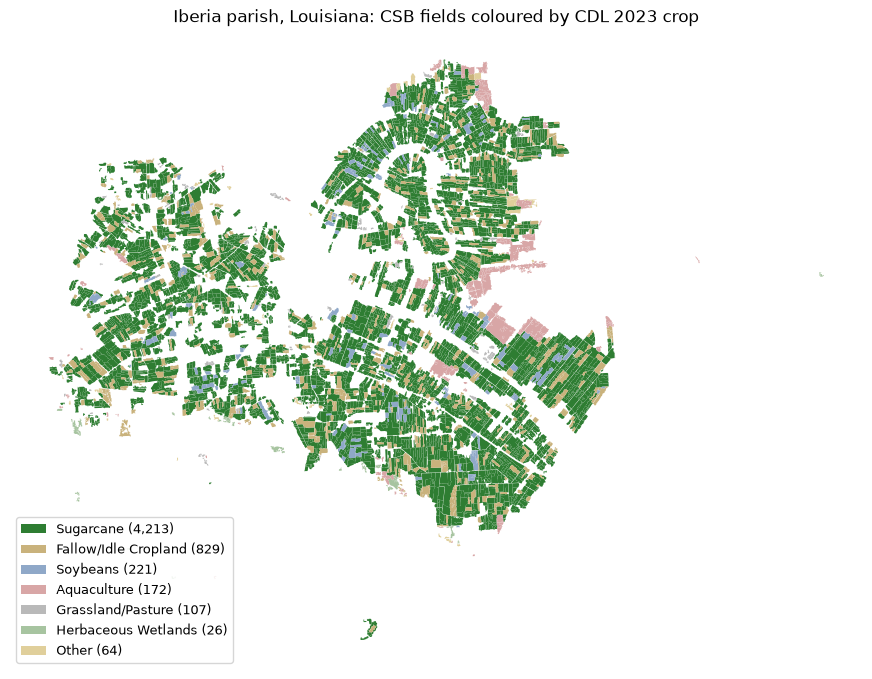

In [6]:
top = p["crop23"].value_counts().index[:6].tolist()
p["crop_map"] = np.where(p["crop23"].isin(top), p["crop23"], "Other")
palette = {"Sugarcane": "#2e7d32"}
others = ["#c9b27c", "#8fa8c8", "#d8a6a6", "#b9b9b9", "#a7c4a0", "#e0cf9b", "#dddddd"]
cats = [c_ for c_ in top + ["Other"] if c_ != "Sugarcane"]
palette.update({c_: others[i % len(others)] for i, c_ in enumerate(cats)})

fig, ax = plt.subplots(figsize=(11, 10))
for cat, col in palette.items():
    sub = p[p["crop_map"] == cat]
    if len(sub):
        sub.plot(ax=ax, color=col, linewidth=0, label=f"{cat} ({len(sub):,})")
ax.legend(loc="lower left", fontsize=9, frameon=True)
ax.set_title(f"{PARISH} parish, Louisiana: CSB fields coloured by CDL 2023 crop")
ax.set_axis_off()
fig.savefig(FIG / "S01_iberia_crop2023.png", dpi=130, bbox_inches="tight")
plt.show()

### Zoom in

A 5 km x 5 km window around the centre of the parish's cane fields, with field outlines, so individual fields are visible.

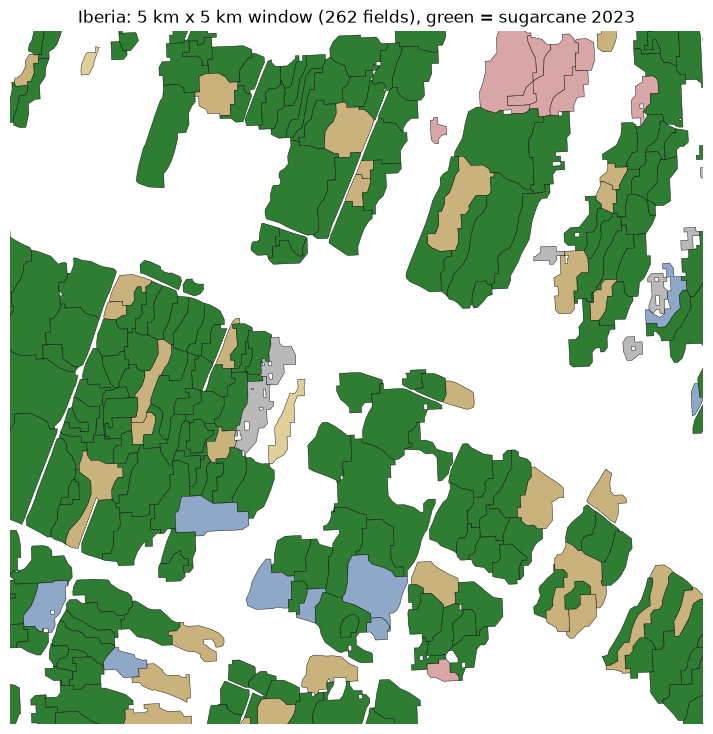

In [7]:
cx, cy = p.loc[p.CDL2023 == 45, "INSIDE_X"].median(), p.loc[p.CDL2023 == 45, "INSIDE_Y"].median()
win = p.cx[cx - 2500:cx + 2500, cy - 2500:cy + 2500]
fig, ax = plt.subplots(figsize=(9, 9))
win.plot(ax=ax, color=win["crop_map"].map(palette), edgecolor="black", linewidth=0.3)
ax.set_title(f"{PARISH}: 5 km x 5 km window ({len(win)} fields), green = sugarcane 2023")
ax.set_xlim(cx - 2500, cx + 2500); ax.set_ylim(cy - 2500, cy + 2500); ax.set_axis_off()
fig.savefig(FIG / "S01_iberia_zoom.png", dpi=130, bbox_inches="tight")
plt.show()

## 6. Field sizes against Sentinel-2 pixels

One Sentinel-2 pixel at 10 m covers 100 m² = 0.01 ha. A field's **pixel count** is roughly `ha / 0.01`. Pixels on the boundary mix the field with its neighbour, so small fields have a high share of "mixed" pixels. Decision rule 2 needs the median field to be at least 0.5 ha (50 pixels).

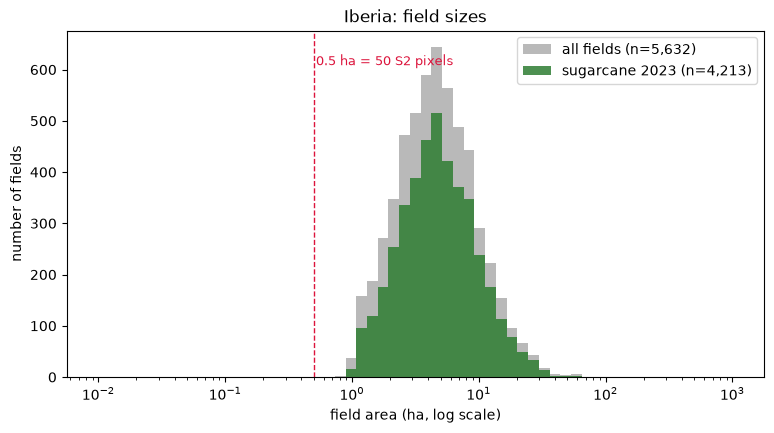

all fields      median 4.55 ha (~455 px) | 10th pct 1.83 ha | 90th pct 11.67 ha | share under 0.5 ha: 0.0%
sugarcane 2023  median 4.65 ha (~465 px) | 10th pct 1.97 ha | 90th pct 11.77 ha | share under 0.5 ha: 0.0%


In [8]:
cane_p = p[p.CDL2023 == 45]
fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.logspace(-2, 3, 60)
ax.hist(p["ha"], bins=bins, color="#b9b9b9", label=f"all fields (n={len(p):,})")
ax.hist(cane_p["ha"], bins=bins, color="#2e7d32", alpha=0.85, label=f"sugarcane 2023 (n={len(cane_p):,})")
ax.axvline(0.5, color="crimson", ls="--", lw=1); ax.text(0.52, ax.get_ylim()[1] * 0.9, "0.5 ha = 50 S2 pixels", color="crimson", fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("field area (ha, log scale)"); ax.set_ylabel("number of fields")
ax.set_title(f"{PARISH}: field sizes"); ax.legend()
fig.savefig(FIG / "S01_iberia_field_sizes.png", dpi=130, bbox_inches="tight")
plt.show()

for name, d in [("all fields", p), ("sugarcane 2023", cane_p)]:
    q = d["ha"].quantile([0.1, 0.5, 0.9])
    print(f"{name:15s} median {q[0.5]:.2f} ha (~{q[0.5] / 0.01:.0f} px) | 10th pct {q[0.1]:.2f} ha | 90th pct {q[0.9]:.2f} ha | "
          f"share under 0.5 ha: {(d.ha < 0.5).mean():.1%}")

## 7. The crop history: how sugarcane behaves over eight years

Sugarcane is **semi-perennial**: planted once, harvested, then regrown from the stubble ("ratoon") for a few years, then the field is usually left fallow or rotated (often soybeans) before replanting. If the CSB labels are sensible, we should see that pattern. This matters for DQ-21 (how to model the cane cycle) and for which years count as "cane".

In [9]:
years = list(range(2018, 2026))
cols = [f"CDL{y}" for y in years]
print("sugarcane fields per year in", PARISH, {y: int((p[f'CDL{y}'] == 45).sum()) for y in years})
print("Louisiana, all parishes:     ", {y: int((la[f'CDL{y}'] == 45).sum()) for y in years})
missing = (p[cols] <= 0).sum()
print("fields with no code (0 = background) per year:", missing.to_dict())

n_cane = (p[cols] == 45).sum(axis=1)
ever = p[n_cane > 0]
print(f"\nfields that were cane in at least one year: {len(ever):,}")
print((n_cane[n_cane > 0]).value_counts().sort_index().rename("fields with N cane years").to_string())

sugarcane fields per year in Iberia {2018: 4165, 2019: 4187, 2020: 4100, 2021: 4143, 2022: 4204, 2023: 4213, 2024: 4019, 2025: 3963}
Louisiana, all parishes:      {2018: 29655, 2019: 29859, 2020: 31241, 2021: 31356, 2022: 31828, 2023: 32373, 2024: 30457, 2025: 30865}
fields with no code (0 = background) per year: {'CDL2018': 0, 'CDL2019': 0, 'CDL2020': 0, 'CDL2021': 0, 'CDL2022': 0, 'CDL2023': 0, 'CDL2024': 0, 'CDL2025': 0}

fields that were cane in at least one year: 5,372
1      71
2      54
3      50
4      92
5     306
6    2925
7    1775
8      99


In [10]:
# Most common 8-year sequences among fields that grew cane at least once.
# Shorthand: C = sugarcane, then the first letters of other crops.
short = {45: "C", 5: "S", 61: "F", 1: "M", 3: "R", 176: "G"}
seq = ever[cols].apply(lambda r: "".join(short.get(v, ".") for v in r), axis=1)
print("legend: C sugarcane, S soybeans, F fallow/idle, M maize(corn), R rice, G grass/pasture, . other\n")
print(seq.value_counts().head(15).to_string())

legend: C sugarcane, S soybeans, F fallow/idle, M maize(corn), R rice, G grass/pasture, . other

CCCCFCCC    429
CCCFCCCC    425
CCFCCCCF    324
CCCFCCCF    285
CCFCCCFC    284
CFCCCCFC    254
FCCCCFCC    245
CFCCCFCC    217
CCFCCCCC    216
FCCCFCCC    176
CCCCCFCC    165
CCCCSCCC    112
CFCCCCCF    103
CCCCCCCC     99
CFCCCCCC     87


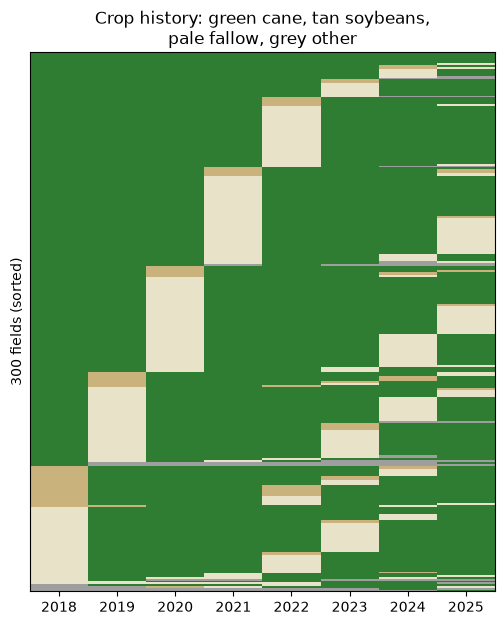

In [11]:
# Picture of the same thing: 300 random cane fields (rows) x 8 years (columns).
samp = ever.sample(min(300, len(ever)), random_state=1)
lut = {45: 0, 5: 1, 61: 2}
arr = samp[cols].apply(lambda col: col.map(lambda v: lut.get(v, 3))).to_numpy()
arr = arr[np.lexsort(arr.T[::-1])]  # sort rows so similar histories group together
from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(6, 7))
ax.imshow(arr, aspect="auto", cmap=ListedColormap(["#2e7d32", "#c9b27c", "#e8e2c8", "#9e9e9e"]), interpolation="nearest")
ax.set_xticks(range(8), years); ax.set_yticks([]); ax.set_ylabel("300 fields (sorted)")
ax.set_title("Crop history: green cane, tan soybeans,\npale fallow, grey other")
fig.savefig(FIG / "S01_iberia_cane_sequences.png", dpi=130, bbox_inches="tight")
plt.show()

## 8. Interactive map (zoom and click a field)

`GeoDataFrame.explore()` draws the fields on a web map (Leaflet, via folium) over satellite or street tiles. Click a field to see its attributes. Only the 5 km window is drawn, to keep the notebook light.

In [12]:
win.to_crs(4326)[["CSBID", "CSBACRES"] + cols + ["crop23", "geometry"]].explore(
    column="crop23", categorical=True, cmap="tab10", tiles="Esri.WorldImagery", style_kwds={"fillOpacity": 0.45, "weight": 0.6})

## 9. Decision rule check

In [13]:
per_year = {y: int((p[f'CDL{y}'] == 45).sum()) for y in years}
med_ha = cane_p["ha"].median()
r1 = min(per_year.values()) >= 1000
r2 = med_ha >= 0.5
r3 = bool((p[cols] > 0).all(axis=None))
print(f"1. >= 1,000 cane fields every year : {r1}  (min {min(per_year.values()):,})")
print(f"2. median cane field >= 0.5 ha     : {r2}  (median {med_ha:.2f} ha, ~{med_ha / 0.01:.0f} S2 pixels)")
print(f"3. a crop code in all 8 years      : {r3}")

1. >= 1,000 cane fields every year : True  (min 3,963)
2. median cane field >= 0.5 ha     : True  (median 4.65 ha, ~465 S2 pixels)
3. a crop code in all 8 years      : True


## 10. Observations and open points

Written up in `docs/research/spikes/S01_csb_fields.md` (observation separate from interpretation). Open points carried to the next spikes:
- The CSB label is the *dominant* CDL class in the field. S02 checks how pure cane fields really are, pixel by pixel.
- Boundaries are fixed for the edition (2018-2025): a field split or merged in between shows up as one polygon with a mixed history.